labels: uint16 (3008, 4096) | instancias: 47 | max id: 79
sample: uint8 (3008, 4096) | rango: 0 - 255


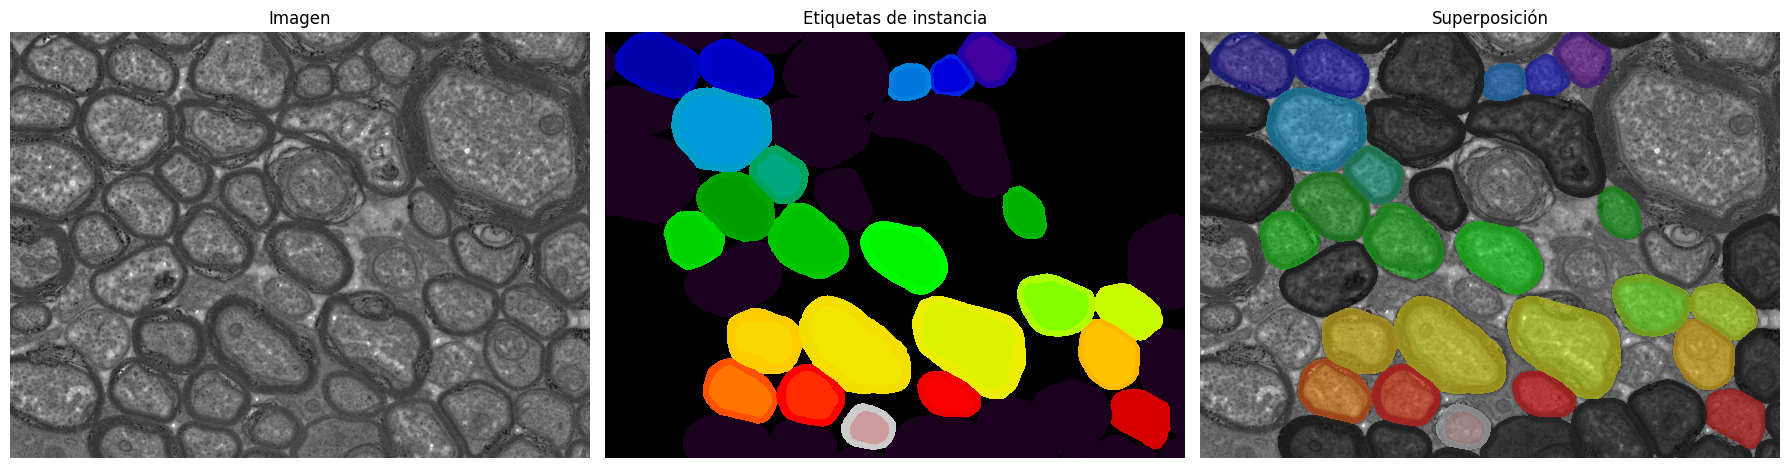

In [1]:
PATH = "/home/stefano/Desktop/Axon/data/train_instance_labels/sample_0001.tif"
SAMPLE_PATH = PATH.replace("train_instance_labels", "train_samples")

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

labels = np.array(Image.open(PATH))        # uint16, 0 = fondo, 1..N = una instancia cada una
sample = np.array(Image.open(SAMPLE_PATH)) # uint8, escala de grises

ids = np.unique(labels)
print("labels:", labels.dtype, labels.shape, "| instancias:", len(ids[ids > 0]), "| max id:", labels.max())
print("sample:", sample.dtype, sample.shape, "| rango:", sample.min(), "-", sample.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(sample, cmap="gray"); axes[0].set_title("Imagen")
axes[1].imshow(labels, cmap="nipy_spectral", interpolation="nearest"); axes[1].set_title("Etiquetas de instancia")
axes[2].imshow(sample, cmap="gray")
axes[2].imshow(np.ma.masked_equal(labels, 0), cmap="nipy_spectral", alpha=0.5, interpolation="nearest")
axes[2].set_title("Superposición")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

0 2234, 3456, 21321,
1 34354, 5343, 34534

In [12]:
np.unique(labels)

array([ 0,  1, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
       25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41,
       44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62,
       63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73], dtype=uint16)

100%|██████████| 266/266 [00:34<00:00,  7.60it/s]


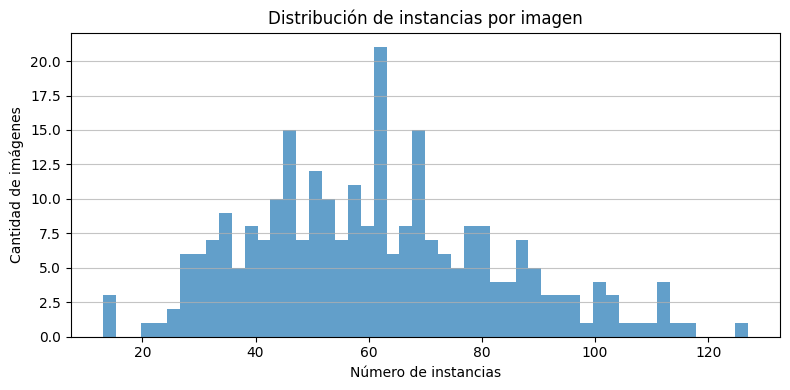

In [ ]:
import os
import numpy as np
from tqdm import tqdm

instancias = []

for filename in tqdm(os.listdir("data/train_instance_labels")):
    if filename.endswith(".tif"):
        path = os.path.join("data/train_instance_labels", filename)
        labels = np.array(Image.open(path))
        ids = np.unique(labels)
        instancias.append(len(ids[ids > 0]))

plt.figure(figsize=(8, 4))
plt.hist(instancias, bins=50, alpha=0.7)
plt.title("Distribución de instancias por imagen")
plt.xlabel("Número de instancias")
plt.ylabel("Cantidad de imágenes")
plt.grid(axis="y", alpha=0.75)
plt.tight_layout()
plt.show()